# 0. Импорт вспомогательных модулей

In [1]:
import csv
import keras
from keras import layers
from keras import regularizers
import numpy as np
import matplotlib.pyplot as plt


2025-03-13 00:23:26.272023: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-03-13 00:23:26.272085: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-03-13 00:23:26.273308: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-13 00:23:26.278410: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


# 1. Подготовка обучающих данных
## 1.1. Выгрузка данных для обучения из файла

In [2]:
def read_from_file(file_name):
    with open(file_name, mode="r", encoding="utf-8") as csvfile:
        reader = csv.DictReader(csvfile)
        features = reader.fieldnames
        read_data = [
            {feature: row[feature] for feature in features} for row in reader
        ]
    return features, read_data


In [3]:
_, read_data = read_from_file("../data/train.csv")


## 1.2. Выделение данных и меток для обучения 

In [4]:
features_to_use = (
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Embarked"
)
train_data_raw = {
    feature: [row[feature] for row in read_data]
    for feature in features_to_use
}
train_labels = np.array([row["Survived"] for row in read_data], dtype="float32")
# train_data_raw.update({"Survived": [row["Survived"] for row in read_data]})


## 1.3. Векторизация

In [5]:
def copy_data(data):
    if isinstance(data, dict):
        return {key: data[key].copy() for key in data}
    elif isinstance(data, list):
        return [val for val in data]
    elif isinstance(data, np.ndarray):
        return np.array([val for val in data], dtype="float32")

def to_one_hot(data, *, master=None):
    encoded_data = copy_data(data)
    if master:
        categories = sorted(set(master))
    elif not master:
        categories = sorted(set(encoded_data))
    for i, val in enumerate(encoded_data):
        # result = np.zeros(len(categories), dtype="float32")
        result = [0 for _ in categories]
        result[categories.index(val)] = 1
        encoded_data[i] = result
    return encoded_data

def vectorize_data(data,
                   *,
                   master=None,
                   cat_ftrs=("Pclass", "Sex", "Embarked"),
                   ignore="Cabin"):
    vectorized_data = copy_data(data)
    num_ftrs = tuple(
        ftr for ftr in vectorized_data.keys()
        if ftr not in cat_ftrs and ftr != ignore
    )
    if master:
        for ftr in cat_ftrs:
            vectorized_data[ftr] = to_one_hot(vectorized_data[ftr],
                                              master=master[ftr])
    elif not master:
        for ftr in cat_ftrs:
            vectorized_data[ftr] = to_one_hot(vectorized_data[ftr])
    for ftr in num_ftrs:
        for i, val in enumerate(vectorized_data[ftr]):
            try:
                vectorized_data[ftr][i] = [float(val)]
            except ValueError:
                vectorized_data[ftr][i] = [None]
    return vectorized_data


train_data_vectorized = vectorize_data(train_data_raw)


## 1.4. Обработка недостающих значений

In [6]:
def get_median_val(data, ftr, group=None):
    data = copy_data(data)
    if group:
        filtered_data = [
            val for i, val in enumerate(data[ftr])
            if (tuple(data["Pclass"][i]), tuple(data["Sex"][i])) == group
        ]
        sorted_data = sorted([val[-1] for val in filtered_data if val[-1] != None])
    else:
        sorted_data = sorted([val[-1] for val in data[ftr] if val[-1] != None])
    if len(sorted_data) % 2 == 0:
        meadian_value = (
            (sorted_data[int(len(sorted_data) / 2)]
             + sorted_data[int(len(sorted_data)/2 + 1)]) / 2
        )
    else:
        meadian_value = sorted_data[int((len(sorted_data) + 1) / 2)]
    return meadian_value

def fill_data(data, ftr="Age"):
    filled_data = copy_data(data)
    non_empty_count = sum(
            [1 for val in filled_data[ftr] if val[-1] != None]
    )
    if non_empty_count < len(filled_data[ftr]):
        median_values = {
            ((1., 0., 0.), (1., 0.)): get_median_val(data, ftr, ((1., 0., 0.), (1., 0.))),    # Pclass: "1", Sex: "female"
            ((1., 0., 0.), (0., 1.)): get_median_val(data, ftr, ((1., 0., 0.), (0., 1.))),    # Pclass: "1", Sex: "male"
            ((0., 1., 0.), (1., 0.)): get_median_val(data, ftr, ((0., 1., 0.), (1., 0.))),    # Pclass: "2", Sex: "female"
            ((0., 1., 0.), (0., 1.)): get_median_val(data, ftr, ((0., 1., 0.), (0., 1.))),    # Pclass: "2", Sex: "male"
            ((0., 0., 1.), (1., 0.)): get_median_val(data, ftr, ((0., 0., 1.), (1., 0.))),    # Pclass: "3", Sex: "female"
            ((0., 0., 1.), (0., 1.)): get_median_val(data, ftr, ((0., 0., 1.), (0., 1.))),    # Pclass: "3", Sex: "male"
        }
        for i, val in enumerate(filled_data[ftr]):
            if not val[-1]:
                filled_data[ftr][i][-1] = median_values[
                    (tuple(filled_data["Pclass"][i]) , tuple(filled_data["Sex"][i]))
                ]
    return filled_data


train_data_filled = fill_data(train_data_vectorized)


## 1.5. Конструирование признаков

In [7]:
def add_features(data):
    data = copy_data(data)
    result = {"AgeGrp": []}#, "HasCabin": []}
    for val in data["Age"]:
        if 0 <= val[-1] < 10:
            result["AgeGrp"].append(0.)
        elif 10 <= val[-1] < 20:
            result["AgeGrp"].append(1.)
        elif 20 <= val[-1] < 30:
            result["AgeGrp"].append(2.)
        elif 30 <= val[-1] < 40:
            result["AgeGrp"].append(3.)
        elif 40 <= val[-1] < 50:
            result["AgeGrp"].append(4.)
        elif 50 <= val[-1] < 60:
            result["AgeGrp"].append(5.)
        elif 60 <= val[-1] < 70:
            result["AgeGrp"].append(6.)
        elif 70 <= val[-1]:
            result["AgeGrp"].append(7.)
    result["AgeGrp"] = to_one_hot(result["AgeGrp"])
    # for val in data["Cabin"]:
    #     if val != "":
    #         result["HasCabin"].append(True)
    #     else:
    #         result["HasCabin"].append(False)
    # result["HasCabin"] = to_one_hot(result["HasCabin"])
    # del data["Cabin"]
    data.update(result)
    return data


train_data_upgraded = add_features(train_data_filled)


## 1.6. Нормализация значений

In [8]:
def normalize_data(data, *, master=None, num_ftrs=("Age", "Parch", "SibSp")):
    normalized_data = copy_data(data)
    if master:
        master_data = copy_data(master)
    elif not master:
        master_data = copy_data(data)
    # num_ftrs = ("Age", "Parch", "SibSp")
    for ftr in num_ftrs:
        mean_val = (
            sum([val[-1] for val in master_data[ftr] if val[-1] != None])
            / len(master_data[ftr])
        )
        std_dev = np.sqrt(
            sum([(val[-1] - mean_val)**2 for val in master_data[ftr]
                 if val[-1] != None])
            / len(master_data[ftr])
        )
        for i, _ in enumerate(normalized_data[ftr]):
            normalized_data[ftr][i][-1] -= mean_val
            normalized_data[ftr][i][-1] /= std_dev
    return normalized_data
    

train_data_normalized = normalize_data(train_data_upgraded)


## 1.7. Формирование массивов данных для обучения

In [9]:
def prepare_data(data):
    return {
        ftr: np.array(data[ftr].copy(), dtype="float32") for ftr in data
    }

train_data = prepare_data(train_data_normalized)


# 2. Обучение модели
## 2.1. Валидация

In [10]:
def build_model(input_data):
    num_of_neurons = 64
    num_of_layers = 2
    dropout_ratio = .50
    inputs = [
        keras.Input(shape=input_data[ftr], name=ftr) for ftr in input_data
    ]
    features = layers.Concatenate()(inputs)
    for i in range(num_of_layers):
        features = layers.Dense(num_of_neurons // 2**i,
                                activation="relu",
                                name=f"Dense-{i+1}")(features)
        features = layers.Dropout(dropout_ratio,
                                  name=f"DropOut-{i+1}")(features)
    outputs = layers.Dense(1, activation="sigmoid", name="Output")(features)
    model = keras.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=5.0e-3),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

def shuffle_data(data):
    if isinstance(data, dict):
        keys = data.keys()
        data = [{ftr: data[ftr][i] for ftr in keys}
                for i in range(len(data["Age"]))]
        np.random.default_rng(1337).shuffle(data)
        data = {ftr: np.array([row[ftr] for row in data]) for ftr in keys}
    elif isinstance(data, np.ndarray):
        np.random.default_rng(1337).shuffle(data)
    return data

def extract_data(data, m, /, size):
    data = copy_data(data)
    if isinstance(data, dict):
        val_data = {}
        train_data = {}
        for ftr in input_dict:
            val_data.update({ftr: data[ftr][m * size:(m+1) * size]})
            train_data.update(
                {
                    ftr: np.concatenate(
                        [data[ftr][:m * size], data[ftr][(m+1) * size:]]
                    )
                }
            )
        return val_data, train_data
    elif isinstance(data, np.ndarray):
        val_labels = data[m*size:(m+1) * size]
        train_labels = np.concatenate([data[:m * size], data[(m+1) * size:]])
        return val_labels, train_labels


p = 5        # number of iterations
k = 10
num_of_val_samples = len(train_labels) // k
num_of_epochs = 50
validation_losses = []
validation_accuracies = []
batch_size = 128
input_dict = {ftr: (train_data[ftr].shape[-1],) for ftr in train_data}
# callbacks = [
#     keras.callbacks.TensorBoard(log_dir="logs")#,
#     # keras.callbacks.EarlyStopping(monitor="val_loss",
#     #                               patience=10,
#     #                               mode="min",
#     #                               baseline=0.30,
#     #                               # restore_best_weights=True,
#     #                               start_from_epoch=10)
# ]
# p-iterations k-fold validation w/ data shuffle
for i in range(p):
    print(f"Iteration #{str(i+1).zfill(len(str(p)))} out of {p}:")
    train_data = shuffle_data(train_data)
    train_labels = shuffle_data(train_labels)
    for j in range(k):
        print(
            f"\tProcessing fold #{str(j+1).zfill(len(str(k)))} out of {k}..."
        )
        val_data, train_data_partial = extract_data(train_data,
                                                    j,
                                                    size=num_of_val_samples)
        val_labels, train_labels_partial = extract_data(train_labels,
                                                        j,
                                                        # extract_labels=True,
                                                        size=num_of_val_samples)
        model = build_model(input_dict)
        history = model.fit(train_data_partial,
                            train_labels_partial,
                            epochs=num_of_epochs,
                            batch_size=batch_size,
                            validation_data=(val_data, val_labels),
                            # callbacks=callbacks,
                            verbose=0)
        validation_loss_history = history.history["val_loss"]
        validation_losses.append(validation_loss_history)
        validation_accuracy_history = history.history["val_accuracy"]
        validation_accuracies.append(validation_accuracy_history)
print("Validation has been completed.")


Iteration #1 out of 5:
	Processing fold #01 out of 10...


2025-03-13 00:23:27.923215: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:26:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-03-13 00:23:27.945569: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:26:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-03-13 00:23:27.945630: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:26:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-03-13 00:23:27.947635: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:26:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-03-13 00:23:27.947687: I external/local_xla/xla/stream_executor

	Processing fold #02 out of 10...
	Processing fold #03 out of 10...
	Processing fold #04 out of 10...
	Processing fold #05 out of 10...
	Processing fold #06 out of 10...
	Processing fold #07 out of 10...
	Processing fold #08 out of 10...
	Processing fold #09 out of 10...
	Processing fold #10 out of 10...
Iteration #2 out of 5:
	Processing fold #01 out of 10...
	Processing fold #02 out of 10...
	Processing fold #03 out of 10...
	Processing fold #04 out of 10...
	Processing fold #05 out of 10...
	Processing fold #06 out of 10...
	Processing fold #07 out of 10...
	Processing fold #08 out of 10...
	Processing fold #09 out of 10...
	Processing fold #10 out of 10...
Iteration #3 out of 5:
	Processing fold #01 out of 10...
	Processing fold #02 out of 10...
	Processing fold #03 out of 10...
	Processing fold #04 out of 10...
	Processing fold #05 out of 10...
	Processing fold #06 out of 10...
	Processing fold #07 out of 10...
	Processing fold #08 out of 10...
	Processing fold #09 out of 10...
	P

## 2.2. Визуализация результатов валидации

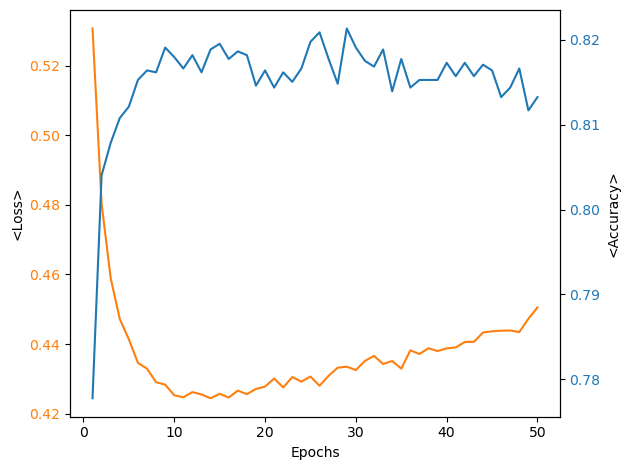

In [11]:
def get_shorten_mean(sequence):
    size = min([len(subseq) for subseq in sequence])
    shorten_sequence = [subseq[:size] for subseq in sequence]
    mean = np.mean(shorten_sequence, axis=0)
    return mean

def add_nans(data):
    length = max([len(arr) for arr in data])
    result = []
    for i, arr in enumerate(data):
        nan_arr = np.full(length, np.nan)
        nan_arr[:len(arr)] = arr
        result.append(nan_arr)
    return result


# validation_losses_average = np.nanmean(add_nans(validation_losses), axis=0)
# validation_accuracies_average = np.nanmean(add_nans(validation_accuracies), axis=0)
# validation_losses_average = get_shorten_mean(validation_losses)
# validation_accuracies_average = get_shorten_mean(validation_accuracies)
validation_losses_average = np.mean(validation_losses, axis=0)
validation_accuracies_average = np.mean(validation_accuracies, axis=0)
fig, ax1 = plt.subplots()
color = "tab:orange"
ax1.plot(
    range(1, len(validation_losses_average)+1),
    validation_losses_average,
    color=color
)
ax1.set_xlabel("Epochs")
ax1.set_ylabel("<Loss>")
ax1.tick_params(axis="y", labelcolor=color)
ax2 = ax1.twinx()
color = "tab:blue"
ax2.plot(
    range(1, len(validation_accuracies_average)+1),
    validation_accuracies_average,
    color=color
)
ax2.set_ylabel("<Accuracy>")
ax2.tick_params(axis="y", labelcolor=color)
fig.tight_layout()
plt.show()


## 2.3. Определение эпохи переобучения

In [12]:
def get_epoch_of_overfitting(sequence, wich="average"):
    if wich == "average":
        overfitting_epoch = np.argmin(sequence)
    elif wich == "max":
        overfitting_epoch = max([len(subseq) - 1 for subseq in sequence])
    return overfitting_epoch

overfitting_epoch = get_epoch_of_overfitting(validation_losses_average)
print(f"Model began to overfit at {overfitting_epoch+1} epoch")
print(f"Average validation accuracy at {overfitting_epoch+1} epoch:"
      f" {round(validation_accuracies_average[overfitting_epoch], 5)}")
print(f"Average validation loss at {overfitting_epoch+1} epoch:"
      f" {round(validation_losses_average[overfitting_epoch], 5)}")


Model began to overfit at 14 epoch
Average validation accuracie at 14 epoch: 0.81888
Average validation loss at 14 epoch: 0.42443


## 2.3. Обучение новой модели

In [13]:
new_model = build_model(input_dict)
print("Fitting new model...")
new_model.fit(train_data,
              train_labels,
              epochs=overfitting_epoch,
              batch_size=batch_size,
              verbose=0)
print("New model has been fitted.")


Fitting new model...
New model has been fitted.


## 2.4. Сохранение модели для последующего использования

In [14]:
# model.save("my-model.keras")
# print("Model has been successfully saved.")

# 3. Подготовка контрольных данных
## 3.1. Выгрузка контрольных данных из файла

In [15]:
_, read_data = read_from_file("../data/test.csv")


## 3.2. Выделение контрольных данных

In [16]:
test_data_raw = {
    feature: [row[feature] for row in read_data]
    for feature in features_to_use
}


## 3.3. Векторизация

In [17]:
test_data_vectorized = vectorize_data(test_data_raw,
                                      master=train_data_raw)


## 3.4. Обработка недостающих значений

In [18]:
test_data_filled = fill_data(test_data_vectorized)


## 3.5. Конструирование признаков

In [19]:
test_data_upgraded = add_features(test_data_filled)


## 3.6. Нормализация значений

In [20]:
test_data_normalized = normalize_data(test_data_upgraded,
                                      master=train_data_upgraded)


## 3.7. Формирование массива контрольных данных

In [21]:
test_data = prepare_data(test_data_normalized)


# 4. Формирование предсказаний
## 4.1. Получение вероятности выживания

In [22]:
predictions_raw = new_model.predict(test_data, verbose=0)


## 4.2. Округление значений до целого

In [23]:
predictions = [
    int(round(prediction[0], 0)) for prediction in predictions_raw
]


## 4.3. Запись результатов в файл

In [24]:
with open("../data/submission.csv", mode="w", encoding="utf-8", newline='') as csvfile:
    writer = csv.DictWriter(csvfile, fieldnames=["PassengerId", "Survived"])
    writer.writeheader()
    for i, prediction in enumerate(predictions):
        writer.writerow(
            {
                "PassengerId": read_data[i]["PassengerId"],
                "Survived": prediction
            }
        )
    print("File has been written.")


File has been written.
